**Marco Antonio Carrilllo Izquierdo**

# Introduccion al Dataset

El objetivo del proyecto es predecir si el cliente se suscribirá a un depósito a plazo

El dataset con el que se trabajo es **Bank Marketing** del repositorio publico *Kaggle,* este dataset contiene informacion de campañas de marketing de un entidad bancaria portuguesa.

La informacion se puede consultar por medio del siguiente enlace: https://archive.ics.uci.edu/dataset/222/bank+marketing

En la descripcion del mismo archivo se mencionan los siguientes 4 archivos:


1) **bank-additional-full.csv** con todos los registros (41188) y 20 entradas, ordenados por fecha (de mayo de 2008 a noviembre de 2010)
2) **bank-additional.csv** con el 10 % de los ejemplos (4119), seleccionados aleatoriamente y 20 entradas.
3) **bank-full.csv** con todos los ejemplos y 17 entradas, ordenados por fecha (versión anterior de este conjunto de datos con menos entradas).
4) **bank.csv** con el 10 % de los ejemplos y 17 entradas, seleccionados aleatoriamente de 3 (versión anterior de este conjunto de datos con menos entradas).

Es por ello que utilizamos solo el archivo **bank-additional-full.csv,** ya que es el que contiene la informacion completa y contiene la siguiente informacion:

**1. Datos del cliente**
- **age**: Edad del cliente
- **job**: Tipo de trabajo
- **marital**: Estado civil
- **education**: Nivel educativo
- **default**: Tiene crédito en mora (sí/no)
- **housing**: Tiene un crédito hipotecario (sí/no)
- **loan**: Tiene un préstamo personal (sí/no)

**2. Datos de la última campaña de marketing**
- **contact**: Tipo de contacto (celular, teléfono fijo)
- **month**: Último mes en que se contactó al cliente
- **day_of_week**: Día de la semana en que se contactó al cliente
- **duration**: Duración de la última llamada (en segundos)

**3. Datos de campañas anteriores**
- **campaign**: Número de contactos realizados en la campaña actual
- **pdays**: Días desde que se contactó al cliente por última vez (-1 si no se contactó antes)
- **previous**: Número de contactos anteriores
- **poutcome**: Resultado de la campaña anterior

**4. Datos socioeconómicos**
- **emp.var.rate**: Tasa de variación del empleo
- **cons.price.idx**: Índice de precios al consumidor
- **cons.conf.idx**: Índice de confianza del consumidor
- **euribor3m**: Tasa de interés Euribor a 3 meses
- **nr.employed**: Número de empleados en la economía  

**Variable objetivo (y)**
- **y**: Indica si el cliente aceptó (`yes`) o no (`no`) el depósito a plazo fijo.

Tome la decision de hacer uso de este dataset primero por el acercamiento que tiene a el campo laboral en el que actualmente laboro (sector bancario), ademas que debido a su amplitud (41188) permite hacer uso de todo lo aprendido en el modulo 1 del diplomado, es decir  realizar una lectura de datos adhoc a los archivos vistos en clase (csv), una limpieza de las columnas, generación de nuevas variables, ingeniería de variables, análisis exploratorio y terminar construyendo una Tabla Analitica de Datos (TAD).

## Librerias

In [1]:
# Librerias habituales
import pandas as pd
import numpy as np
import os
import gc
import seaborn as sns
import matplotlib.pyplot as plt
import cufflinks as cf
from sklearn import set_config
from functools import reduce
from datetime import datetime, timedelta

# Valores faltantes
from sklearn.impute import SimpleImputer
# Preprocessing
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import StandardScaler
#Preparacion de Modelo
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
#PCA
from sklearn.decomposition import PCA

# Enviroment setup
pd.set_option("display.max_columns", None)
pd.set_option('display.float_format', lambda x: '%.3f' % x)

# Lectura de Datos

El primer paso que realizamos fue leer la base de datos que vamos a utilizar:

In [2]:
df = pd.read_csv('bank-additional-full.csv', sep = ';')

In [3]:
df.head(6) 

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,261,1,999,0,nonexistent,1.100,93.994,-36.400,4.857,5191.000,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,149,1,999,0,nonexistent,1.100,93.994,-36.400,4.857,5191.000,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,226,1,999,0,nonexistent,1.100,93.994,-36.400,4.857,5191.000,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,151,1,999,0,nonexistent,1.100,93.994,-36.400,4.857,5191.000,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,307,1,999,0,nonexistent,1.100,93.994,-36.400,4.857,5191.000,no
5,45,services,married,basic.9y,unknown,no,no,telephone,may,mon,198,1,999,0,nonexistent,1.100,93.994,-36.400,4.857,5191.000,no


# Analisis Exploratorio

El segundo paso que se realizo fue el analisis exploratio de las variables, en el tenemos qcomo objetivo comprender cual es la estructura de los datos de nuestra base, su frecuencia, distribución, si tiene algun tipo de valor atípico o si alguna de las variables tiene una gran cantidad de valores faltantes. 

## Limpieza de Datos

El primer paso, a gusto personal es revisar si hay algun valor que sea NaN/Null dentro del data frame, para evitar procesar informacion que no nos es util y que ocupa memoria, ademas de que nos evitara encontrarnos con errores mas adelante en la Ingenieria de Variables

In [4]:
df.isna().sum()

age               0
job               0
marital           0
education         0
default           0
housing           0
loan              0
contact           0
month             0
day_of_week       0
duration          0
campaign          0
pdays             0
previous          0
poutcome          0
emp.var.rate      0
cons.price.idx    0
cons.conf.idx     0
euribor3m         0
nr.employed       0
y                 0
dtype: int64

Aqui ocurre una situacion rara, porque en el conteno de NaN parece que todo esta en orden, esto es algo que se menciona en la descricpion de la base de datos en *Kaggle,* sin embargo, en la columna default hay valores que aparecen como unkown.

Este descubrimiento se nos dio mas adelante cuando estabamos realizando los histogramas para las variables discretas y continuas, pero amen de seguir la congruencia establecida para el proyecto la colocaremos de este lado:

Si bien hay mas variables que tienen valores como *unknown,* la mas signfifcativa dado por los valores tan altos es **default** por lo que procederemos a revisar cual es el numero de valores con esa categoria

In [5]:
df['default'].value_counts()

default
no         32588
unknown     8597
yes            3
Name: count, dtype: int64

In [6]:
df['default'].value_counts(normalize=True) * 100

default
no        79.120
unknown   20.873
yes        0.007
Name: proportion, dtype: float64

Son demasiados valores como **unknown** es basicamente el 21% de los datos, por lo que imputar no es una opcion viable. Si observamos cual es la descripcion de esta variable que esta al inico de este codigo encontramos lo siguiente:

- **default**: Tiene crédito en mora (sí/no)

Por lo que no es una variable que sea de suma importancia dentro de nuestro analisis, por lo tanto, vamos a eliminarla de nuestra base

In [7]:
df.drop('default', axis=1, inplace=True)

## Variables

Ahora, para poder categorizar el tipo de dato que tenemos para cada columna, vamos a extraer el tipo:

In [8]:
for col in df.columns:
    print(f'{col} -> {df[col].apply(type).unique()}')

age -> [<class 'int'>]
job -> [<class 'str'>]
marital -> [<class 'str'>]
education -> [<class 'str'>]
housing -> [<class 'str'>]
loan -> [<class 'str'>]
contact -> [<class 'str'>]
month -> [<class 'str'>]
day_of_week -> [<class 'str'>]
duration -> [<class 'int'>]
campaign -> [<class 'int'>]
pdays -> [<class 'int'>]
previous -> [<class 'int'>]
poutcome -> [<class 'str'>]
emp.var.rate -> [<class 'float'>]
cons.price.idx -> [<class 'float'>]
cons.conf.idx -> [<class 'float'>]
euribor3m -> [<class 'float'>]
nr.employed -> [<class 'float'>]
y -> [<class 'str'>]


### Variables Continuas

In [9]:
continuas = ['age','duration','campaign','pdays','previous','emp.var.rate', 'cons.conf.idx', 'cons.price.idx','euribor3m','nr.employed']

In [10]:
df[continuas] = df[continuas].astype(float)

### Variables Discretas

In [11]:
discretas = ['job','marital','education','housing','loan','contact','month','day_of_week','poutcome']

In [12]:
df[discretas] = df[discretas].astype(object)

### Unidad Muestral/Variable Objetivo

In [13]:
# Renombraremos la variable objetivo
target = 'y'
# La variable objetivo es dummy, la vamos a tratar de esta forma
df['y'] = df['y'].map({'yes':1, 'no':0})

In [14]:
pd.DataFrame(df["y"].value_counts(1))

,proportion
y,
0,0.887
1,0.113


In [15]:
# Recolectamos la basura para optimizar la memoria
gc.collect()

31

## Visualizacion de las Variables

Ahora meramente lo que haremos sera observar el comportamiento de las variables discretas y continuas en un histograma

### Continuas

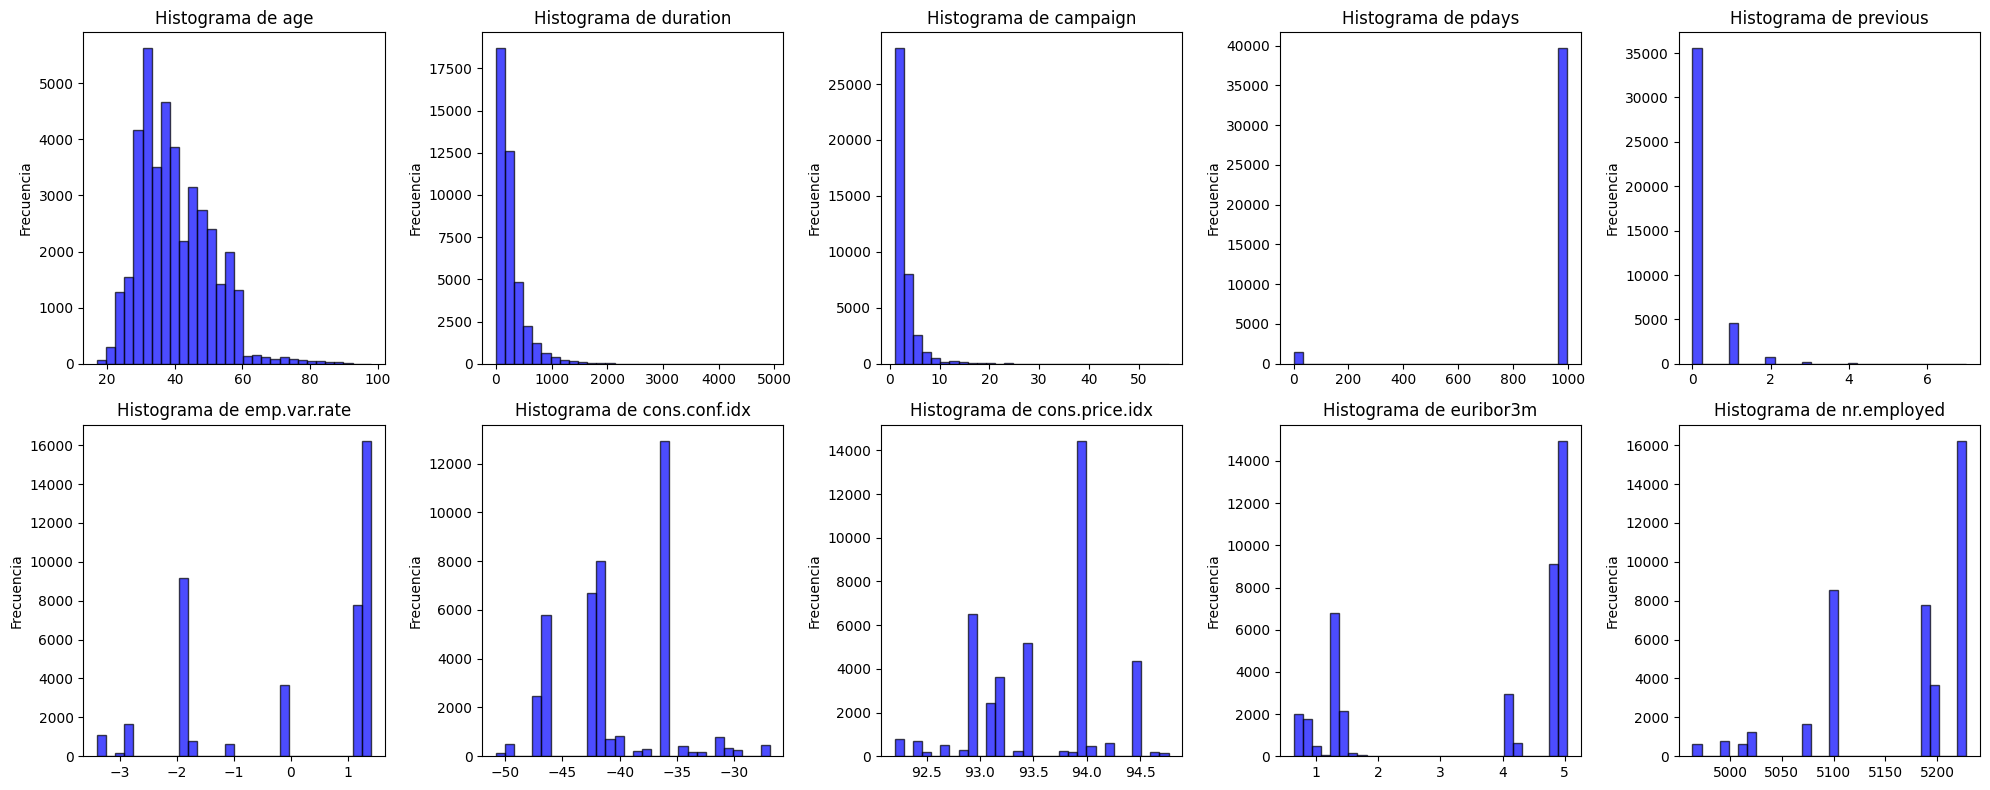

In [16]:
fig, axes = plt.subplots(2, 5, figsize=(20, 8))  
axes = axes.flatten() 

for i, col in enumerate(continuas):
    axes[i].hist(df[col].dropna(), bins=30, alpha=0.7, color='blue', edgecolor='black')
    axes[i].set_title(f'Histograma de {continuas[i]}')
    axes[i].set_ylabel('Frecuencia')

plt.tight_layout()
plt.show()

### Discretas

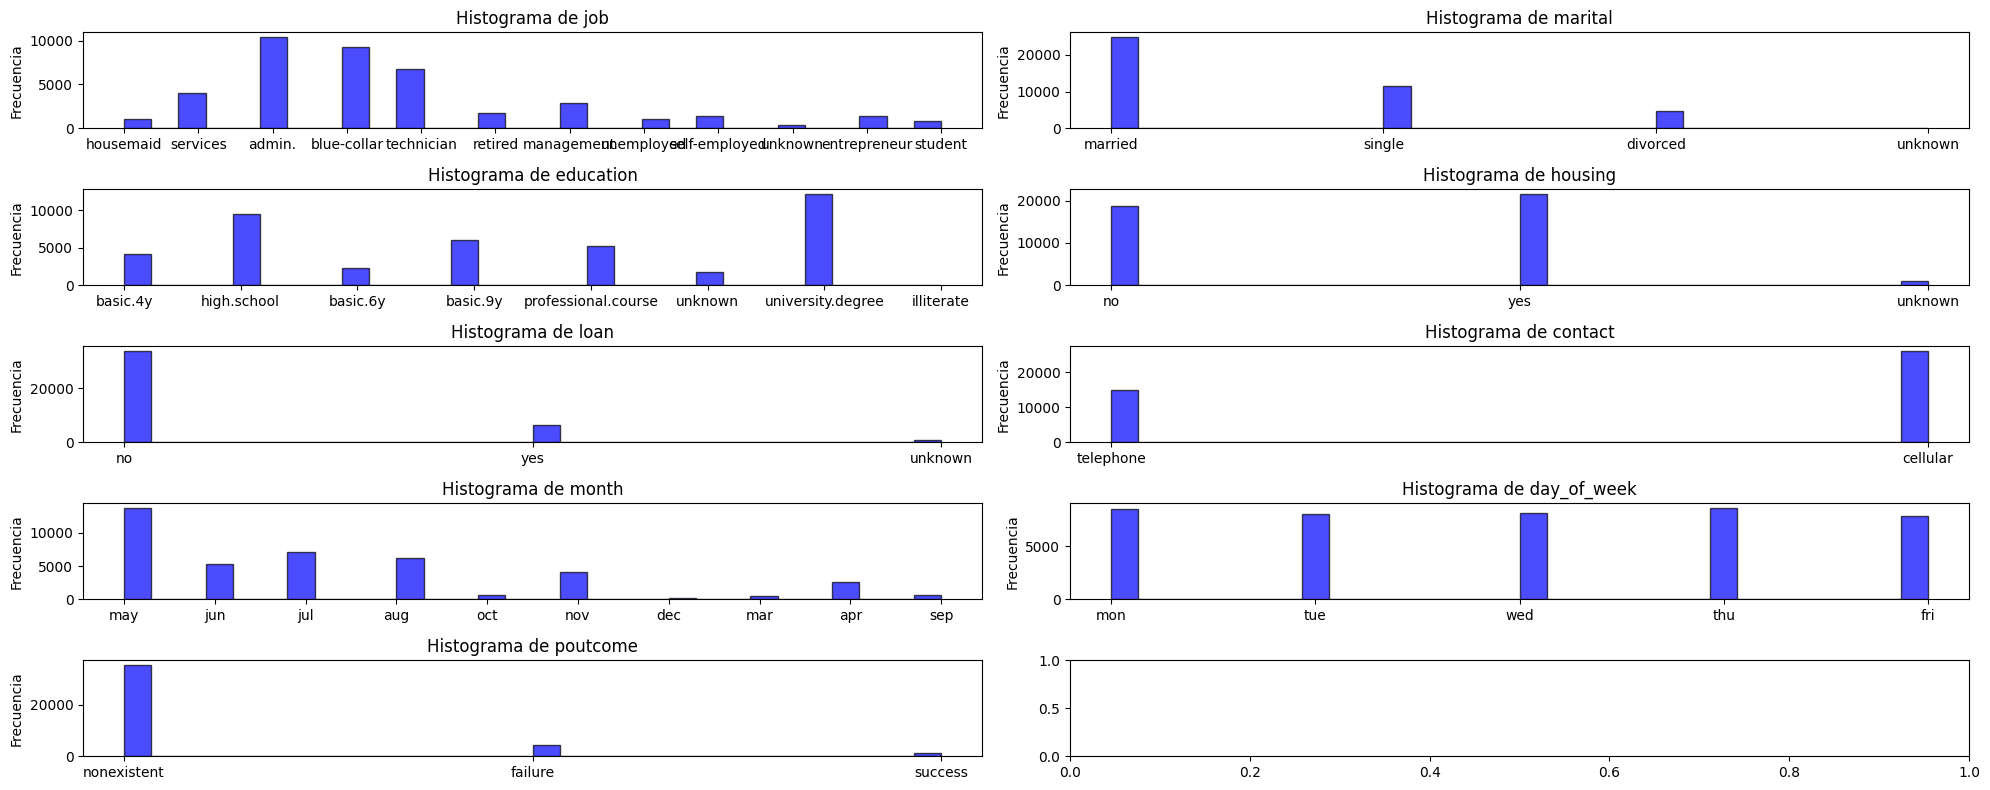

In [17]:
fig, axes = plt.subplots(5, 2, figsize=(20, 8))  
axes = axes.flatten() 

for i, col in enumerate(discretas):
    axes[i].hist(df[col].dropna(), bins=30, alpha=0.7, color='blue', edgecolor='black')
    axes[i].set_title(f'Histograma de {discretas[i]}')
    axes[i].set_ylabel('Frecuencia')

plt.tight_layout()
plt.show()

A partir de los hitogramas anteriores, se puede ver que las variables *loan*, *marital* y *housing* tienen valores como unkown, esto nos impediria tratarlas como binarias, entonces, veremos que porcentaje de estas variables esta dentro de la columna para definir si los mantenemos o los imputaremos con la moda

In [18]:
df['loan'].value_counts(normalize=True) * 100

loan
no        82.427
yes       15.169
unknown    2.404
Name: proportion, dtype: float64

In [19]:
df['marital'].value_counts(normalize=True) * 100

marital
married    60.522
single     28.086
divorced   11.197
unknown     0.194
Name: proportion, dtype: float64

In [20]:
df['housing'].value_counts(normalize=True) * 100

housing
yes       52.384
no        45.212
unknown    2.404
Name: proportion, dtype: float64

Para los 3 casos es menos del 5%, por lo cual me parece factible imputadr los valores con la moda para as[i poder tratar estas variables como binarias

In [21]:
#Usamos el metodo SimpleImputer: Para este caso no es necesario crear otro vector con el nombre de las columnas que queremos imputar, ya que todos comparten el 
# 'missing value' que es unkown y el resto de variables discretas no lo tienen
imputar = SimpleImputer(missing_values="unknown", strategy = 'most_frequent')
#Lo aplicamos a las discretas
df[discretas] = imputar.fit_transform(df[discretas])

Y ahora vamos a tratarla como una variable binaria:

In [22]:
df['loan'] = df['loan'].map({'yes':1, 'no':0})

In [23]:
df['housing'] = df['housing'].map({'yes':1, 'no':0})

Aprovechamos que la variable contact tambien se puede tratar de esa manera:

In [24]:
df['contact'] = df['contact'].map({'cellular':1, 'telephone':0})

Y ahora solo corroboramos que se hayan hecho los cambios correctamente

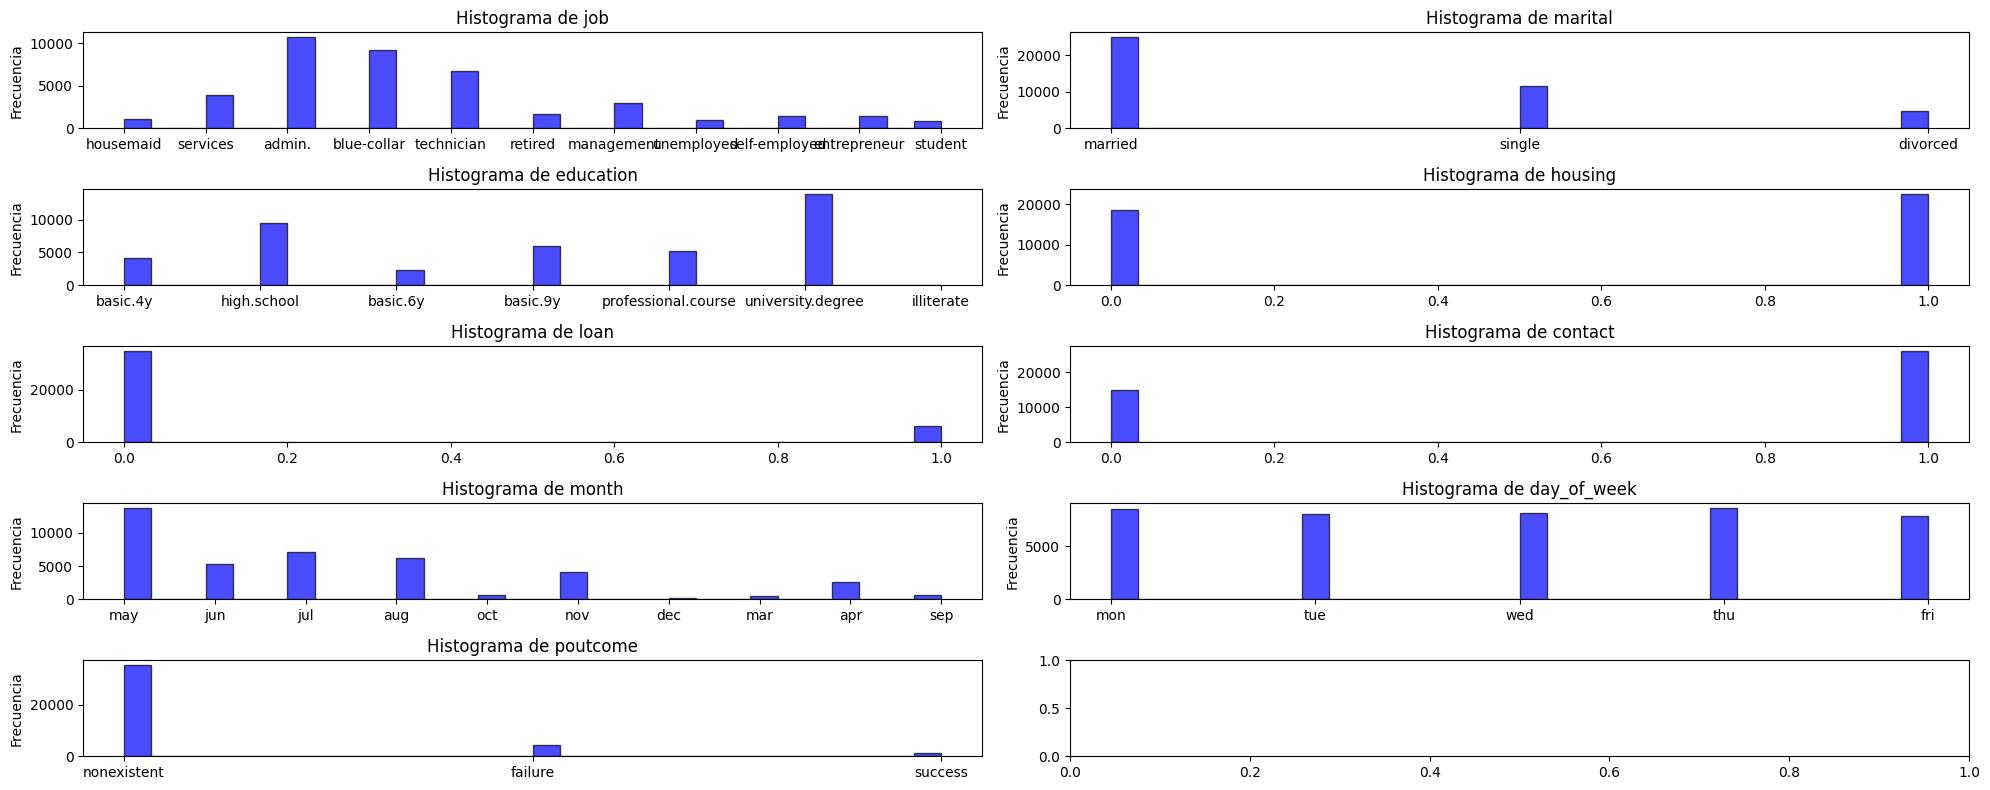

In [25]:
fig, axes = plt.subplots(5, 2, figsize=(20, 8))  
axes = axes.flatten() 

for i, col in enumerate(discretas):
    axes[i].hist(df[col].dropna(), bins=30, alpha=0.7, color='blue', edgecolor='black')
    axes[i].set_title(f'Histograma de {discretas[i]}')
    axes[i].set_ylabel('Frecuencia')

plt.tight_layout()
plt.show()

Ahora lo que haremos sera tratar las vairbales del tiempo para poder hacer uso de ventanas de tiempo:

# Ingenieria de Variables

Ahora, procedimos a relizar la ingenieria de variables para ayudar al modelo a mejorar sus predicciones creando nuevas variables o agrupandolas.

## Analisis de Variables Categoricas

Para entender de mejor manera la a distribución de nuestras variables categóricas/discretas hicimos uso del codigo que realizamos en calse para observar las frecuencias de nuestras variables, los resultados mostraron lo siguiente:

In [26]:
#Funcion Definida en Clase
def frecuencias(df, var):
    if type(var) != list:
        var = [var]

    for v in var:
        # Frecuencia Absoluta
        frecuencias_abs = df[v].value_counts().sort_index().to_frame(name='Frecuencia Absoluta')

        # Frecuencia Relativa
        frecuencias_abs['Frecuencia Relativa'] = frecuencias_abs['Frecuencia Absoluta'] / frecuencias_abs['Frecuencia Absoluta'].sum()

        # Frecuencia Acumulada Absoluta
        frecuencias_abs['Frecuencia Acumulada Absoluta'] = frecuencias_abs['Frecuencia Absoluta'].cumsum()

        # Frecuencia Acumulada Relativa
        frecuencias_abs['Frecuencia Acumulada Relativa'] = frecuencias_abs['Frecuencia Relativa'].cumsum()

        print(f"\nFrecuencias para la variable {v}")
        display(frecuencias_abs)
        print("\n")

In [27]:
frecuencias( df , discretas)


Frecuencias para la variable job


,Frecuencia Absoluta,Frecuencia Relativa,Frecuencia Acumulada Absoluta,Frecuencia Acumulada Relativa
job,,,,
admin.,10752,0.261,10752,0.261
blue-collar,9254,0.225,20006,0.486
entrepreneur,1456,0.035,21462,0.521
housemaid,1060,0.026,22522,0.547
management,2924,0.071,25446,0.618
retired,1720,0.042,27166,0.660
self-employed,1421,0.035,28587,0.694
services,3969,0.096,32556,0.790
student,875,0.021,33431,0.812





Frecuencias para la variable marital


,Frecuencia Absoluta,Frecuencia Relativa,Frecuencia Acumulada Absoluta,Frecuencia Acumulada Relativa
marital,,,,
divorced,4612,0.112,4612,0.112
married,25008,0.607,29620,0.719
single,11568,0.281,41188,1.000





Frecuencias para la variable education


...

,Frecuencia Absoluta,Frecuencia Relativa,Frecuencia Acumulada Absoluta,Frecuencia Acumulada Relativa
month,,,,
apr,2632,0.064,2632,0.064
aug,6178,0.150,8810,0.214
dec,182,0.004,8992,0.218
jul,7174,0.174,16166,0.392
jun,5318,0.129,21484,0.522
mar,546,0.013,22030,0.535
may,13769,0.334,35799,0.869
nov,4101,0.100,39900,0.969
oct,718,0.017,40618,0.986





Frecuencias para la variable day_of_week


,Frecuencia Absoluta,Frecuencia Relativa,Frecuencia Acumulada Absoluta,Frecuencia Acumulada Relativa
day_of_week,,,,
fri,7827,0.190,7827,0.190
mon,8514,0.207,16341,0.397
thu,8623,0.209,24964,0.606
tue,8090,0.196,33054,0.803
wed,8134,0.197,41188,1.000





Frecuencias para la variable poutcome


,Frecuencia Absoluta,Frecuencia Relativa,Frecuencia Acumulada Absoluta,Frecuencia Acumulada Relativa
poutcome,,,,
failure,4252,0.103,4252,0.103
nonexistent,35563,0.863,39815,0.967
success,1373,0.033,41188,1.000


Se pudo observar que para las variables *job*, *marital*, *education*  tienen varios grupos que no contienen mucha informacion, por lo que podriamos agruparlos para reducir la frecuencia y ayudar al modelo 

Para **job** los valores "student" (2.1%), "housemaid" (2.6%) y "unemployed" (2.5%), "self-employed" (3.5%) y  "entrepreneur" (3.5%) tienen baja frecuencia, entonces los agruparemos en uno solo

In [28]:
df['job'] = df['job'].replace(['student', 'housemaid', 'unemployed', 'self-employed', 'entrepreneur'], 'otros')

Para **marital**  agruparemos single (28.1%) y divorced (11.2%) para convertirlo en binaria, ya que de alguna manera tienen una cierta similitud con respecto al estatus contrario, es decir manetener la dualidad casado y no casado.

In [29]:
df['marital'] = df['marital'].apply(lambda x: 1 if x == 'married' else 0)

Para la variable education vamos a agrupar todos los basics y a borrar los registros que tienen *illiterate* porque solo son 18 registros, osea que no son significativos para nuestro proposito

In [30]:
df['education'] = df['education'].replace(['basic.4y', 'basic.6y', 'basic.9y'], 'basic')

In [31]:
df = df[df['education'] != 'illiterate']

In [32]:
# Recolectamos la basura para optimizar la memoria
gc.collect()

35314

In [33]:
frecuencias( df , discretas)


Frecuencias para la variable job


,Frecuencia Absoluta,Frecuencia Relativa,Frecuencia Acumulada Absoluta,Frecuencia Acumulada Relativa
job,,,,
admin.,10751,0.261,10751,0.261
blue-collar,9246,0.225,19997,0.486
management,2924,0.071,22921,0.557
otros,5820,0.141,28741,0.698
retired,1717,0.042,30458,0.740
services,3969,0.096,34427,0.836
technician,6743,0.164,41170,1.000





Frecuencias para la variable marital


,Frecuencia Absoluta,Frecuencia Relativa,Frecuencia Acumulada Absoluta,Frecuencia Acumulada Relativa
marital,,,,
0,16177,0.393,16177,0.393
1,24993,0.607,41170,1.000





Frecuencias para la variable education


...

,Frecuencia Absoluta,Frecuencia Relativa,Frecuencia Acumulada Absoluta,Frecuencia Acumulada Relativa
month,,,,
apr,2630,0.064,2630,0.064
aug,6173,0.150,8803,0.214
dec,182,0.004,8985,0.218
jul,7169,0.174,16154,0.392
jun,5318,0.129,21472,0.522
mar,546,0.013,22018,0.535
may,13766,0.334,35784,0.869
nov,4098,0.100,39882,0.969
oct,718,0.017,40600,0.986





Frecuencias para la variable day_of_week


,Frecuencia Absoluta,Frecuencia Relativa,Frecuencia Acumulada Absoluta,Frecuencia Acumulada Relativa
day_of_week,,,,
fri,7823,0.190,7823,0.190
mon,8513,0.207,16336,0.397
thu,8617,0.209,24953,0.606
tue,8085,0.196,33038,0.802
wed,8132,0.198,41170,1.000





Frecuencias para la variable poutcome


,Frecuencia Absoluta,Frecuencia Relativa,Frecuencia Acumulada Absoluta,Frecuencia Acumulada Relativa
poutcome,,,,
failure,4251,0.103,4251,0.103
nonexistent,35547,0.863,39798,0.967
success,1372,0.033,41170,1.000


Lo siguiente fue codificar las variables cateogricas con la nueva agrupacion que tenemos, pudimos haberlo hecho desde antes, pero me parece que haber reducido las opciones para cada variable categorica que no es binaria es buen idea ya que evita procesa informacion que no aporta mucho al modelo

### Codificando Variables Categoricas

In [34]:
df

,age,job,marital,education,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56.000,otros,1,basic,0,0,0,may,mon,261.000,1.000,999.000,0.000,nonexistent,1.100,93.994,-36.400,4.857,5191.000,0
1,57.000,services,1,high.school,0,0,0,may,mon,149.000,1.000,999.000,0.000,nonexistent,1.100,93.994,-36.400,4.857,5191.000,0
2,37.000,services,1,high.school,1,0,0,may,mon,226.000,1.000,999.000,0.000,nonexistent,1.100,93.994,-36.400,4.857,5191.000,0
3,40.000,admin.,1,basic,0,0,0,may,mon,151.000,1.000,999.000,0.000,nonexistent,1.100,93.994,-36.400,4.857,5191.000,0
4,56.000,services,1,high.school,0,1,0,may,mon,307.000,1.000,999.000,0.000,nonexistent,1.100,93.994,-36.400,4.857,5191.000,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
41183,73.000,retired,1,professional.course,1,0,1,nov,fri,334.000,1.000,999.000,0.000,nonexistent,-1.100,94.767,-50.800,1.028,4963.600,1
41184,46.000,blue-collar,1,professional.course,0,0,1,nov,fri,383.000,1.000,999.000,0.000,nonexistent,-1.100,94.767,-50.800,1.028,4963.600,0
41185,56.000,retired,1,university.degree,1,0,1,nov,fri,189.000,2.000,999.000,0.000,nonexistent,-1.100,94.767,-50.800,1.028,4963.600,0
41186,44.000,technician,1,professional.course,0,0,1,nov,fri,442.000,1.000,999.000,0.000,nonexistent,-1.100,94.767,-50.800,1.028,4963.600,1


In [35]:
df_enc = pd.get_dummies(df, columns=['job',"education", "poutcome"],drop_first=True)

mes_map = {'jan': 1,'feb': 2,'mar': 3,'apr': 4,'may': 5,'jun': 6,'jul': 7,'aug': 8,'sep': 9,'oct': 10,'nov': 11,'dec': 12}
df_enc['month'] = df_enc['month'].map(mes_map)

dia_map = {'mon': 1,'tue': 2,'wed': 3,'thu': 4,'fri': 5,'sat': 6,'sun': 7}
df_enc['day_of_week'] = df_enc['day_of_week'].map(dia_map)

In [36]:
df_enc

,age,marital,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y,job_blue-collar,job_management,job_otros,job_retired,job_services,job_technician,education_high.school,education_professional.course,education_university.degree,poutcome_nonexistent,poutcome_success
0,56.000,1,0,0,0,5,1,261.000,1.000,999.000,0.000,1.100,93.994,-36.400,4.857,5191.000,0,False,False,True,False,False,False,False,False,False,True,False
1,57.000,1,0,0,0,5,1,149.000,1.000,999.000,0.000,1.100,93.994,-36.400,4.857,5191.000,0,False,False,False,False,True,False,True,False,False,True,False
2,37.000,1,1,0,0,5,1,226.000,1.000,999.000,0.000,1.100,93.994,-36.400,4.857,5191.000,0,False,False,False,False,True,False,True,False,False,True,False
3,40.000,1,0,0,0,5,1,151.000,1.000,999.000,0.000,1.100,93.994,-36.400,4.857,5191.000,0,False,False,False,False,False,False,False,False,False,True,False
4,56.000,1,0,1,0,5,1,307.000,1.000,999.000,0.000,1.100,93.994,-36.400,4.857,5191.000,0,False,False,False,False,True,False,True,False,False,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
41183,73.000,1,1,0,1,11,5,334.000,1.000,999.000,0.000,-1.100,94.767,-50.800,1.028,4963.600,1,False,False,False,True,False,False,False,True,False,True,False
41184,46.000,1,0,0,1,11,5,383.000,1.000,999.000,0.000,-1.100,94.767,-50.800,1.028,4963.600,0,True,False,False,False,False,False,False,True,False,True,False
41185,56.000,1,1,0,1,11,5,189.000,2.000,999.000,0.000,-1.100,94.767,-50.800,1.028,4963.600,0,False,False,False,True,False,False,False,False,True,True,False
41186,44.000,1,0,0,1,11,5,442.000,1.000,999.000,0.000,-1.100,94.767,-50.800,1.028,4963.600,1,False,False,False,False,False,True,False,True,False,True,False


## Estandarizacion de las Variables Numericas

Ahora vamos a estandarizar las variables numericas

In [37]:
scaler = StandardScaler()

In [38]:
df_enc[['age', 'duration', 'campaign']] = scaler.fit_transform(df_enc[['age', 'duration', 'campaign']])

In [39]:
df_enc[['emp.var.rate', 'cons.price.idx', 'cons.conf.idx','euribor3m', 'nr.employed']] = scaler.fit_transform(df_enc[['emp.var.rate', 'cons.price.idx', 'cons.conf.idx','euribor3m', 'nr.employed']])

In [40]:
df=df_enc

In [41]:
del df_enc

Este paso pudo haberse realiado anteriormente, sin embargo no lo habiamos notado hasta los analsis Bivariados y de Colinealidad, pero amen de no incluirlo dentro del analisis lo haremos aqui:  Por la definicion la variable duration no deber[ia de estar en el modelo si lo que buscamos es predecir, entonces lo que haremos sera borrarla del dataframe

In [42]:
df = df.drop('duration', axis=1)

In [43]:
continuas = ['age', 'campaign', 'pdays', 'previous', 'emp.var.rate', 'cons.price.idx','cons.conf.idx', 'euribor3m', 'nr.employed']

In [44]:
discretas = ['marital','housing','loan','contact','month','day_of_week']

# Analisis Bivariado

### Analisis Bivariado: Discretas vs Variable Objetivo

Una vez que termianmos de analizar la frecuencia de las variables categoricas, realizaremos un analisis con graficas para entender cómo se distribuye la variable objetivo respecto de las diferentes categorías de las variables como job, marital, education, housing, loan, contact, month, day_of_week, y poutcome

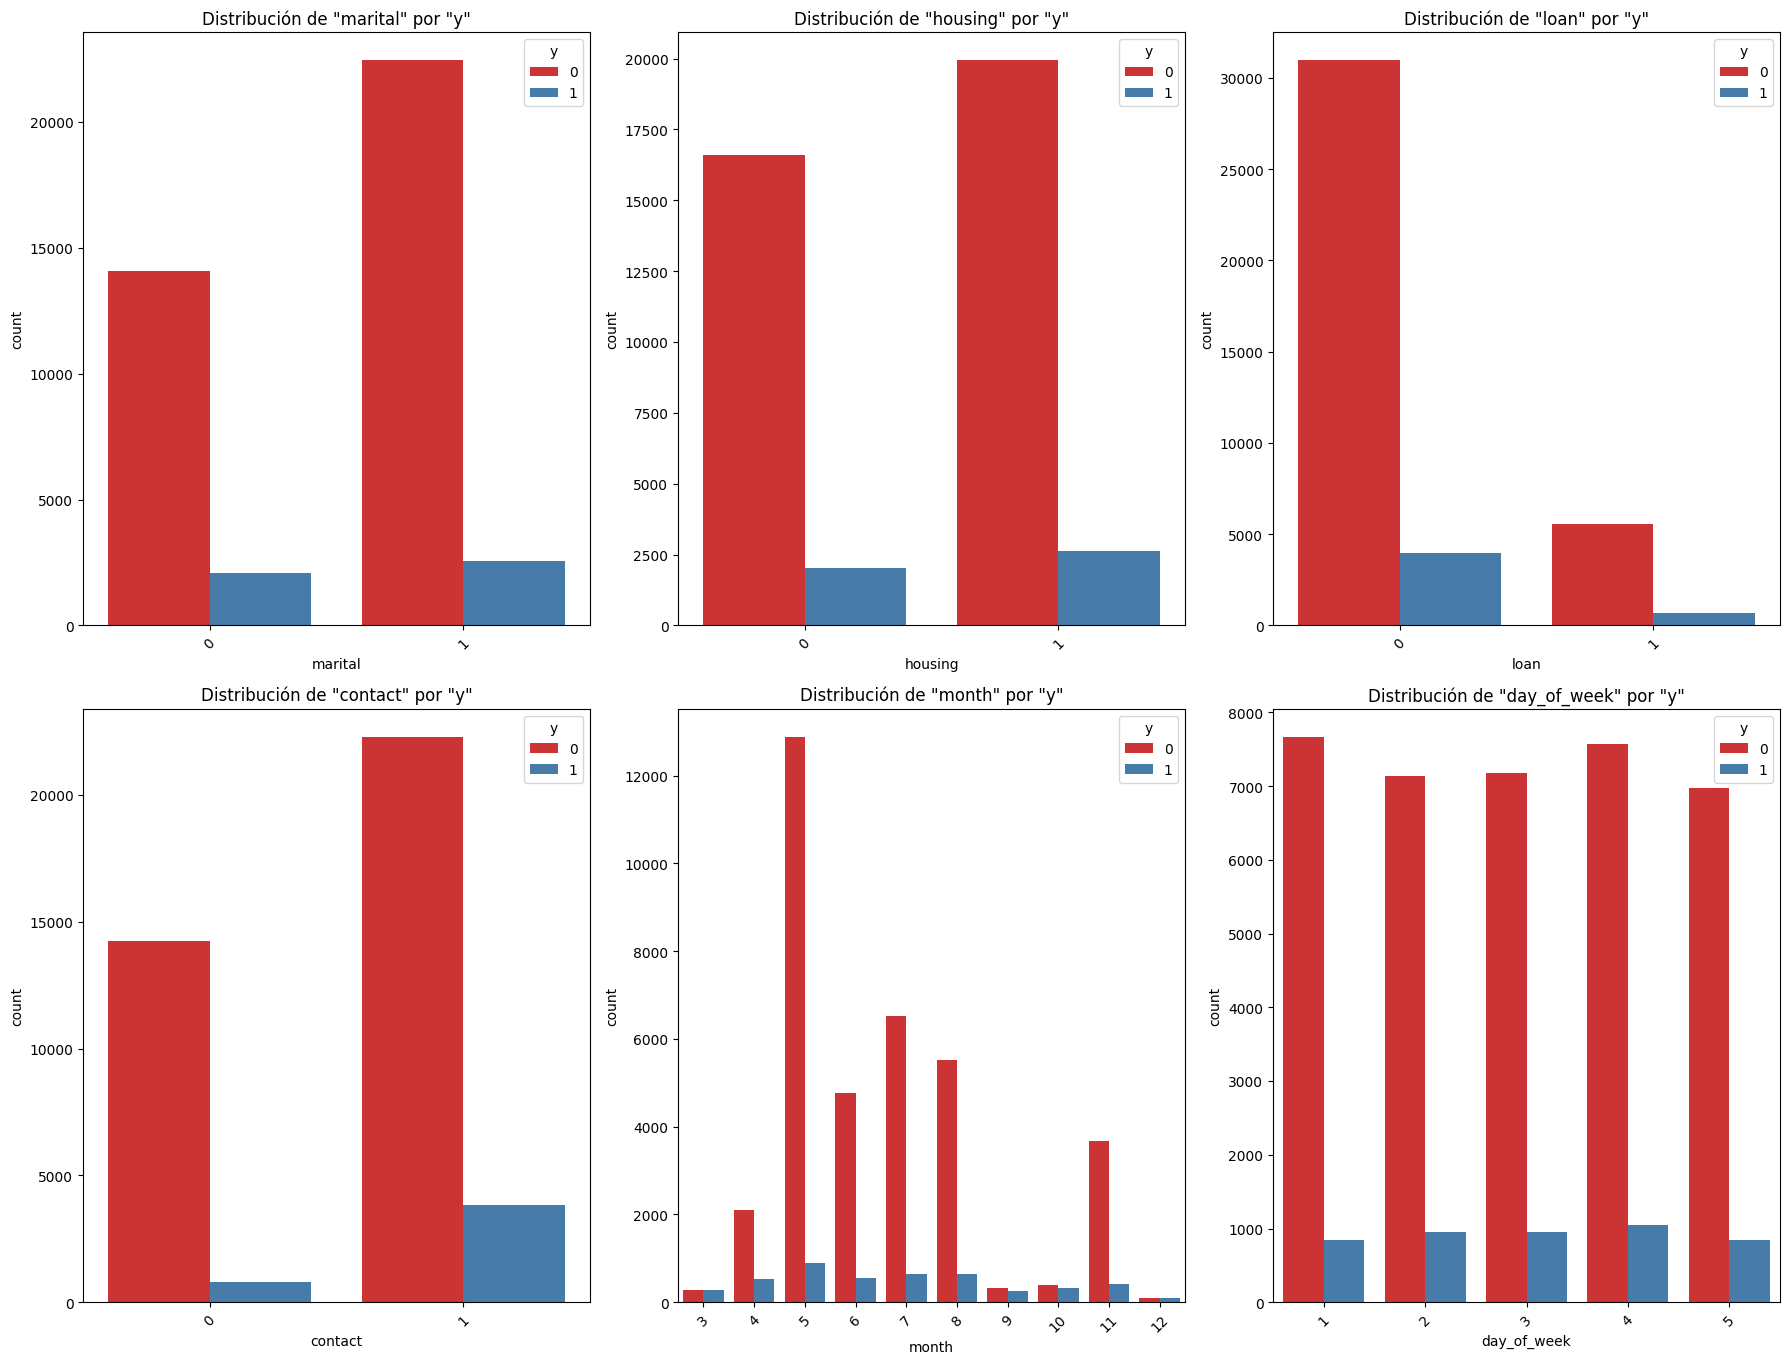

In [45]:
# Configuración del grid de gráficos (3x3 para 9 variables)
plt.figure(figsize=(18, 20))  # Tamaño grande para buena visualización
plt.subplots_adjust(hspace=0.5, wspace=0.3)  # Ajustar espacios

# Generar cada subplot
for i, var in enumerate(discretas, 1):
    plt.subplot(3, 3, i)  # 3 filas, 3 columnas
    sns.countplot(x=var, hue='y', data=df, palette='Set1')
    plt.title(f'Distribución de "{var}" por "y"')
    plt.xticks(rotation=45)
    plt.legend(title='y', loc='upper right')

plt.tight_layout()
plt.show()

Pareciera que no hay una distribucion diferente entre aquellos que aceptaron o no el deposito a plazo fijo

### Analisis Bivariado: Continuas vs Variable Objetivo

Se hizo el analisis anologo pero ahora con las variables continuas

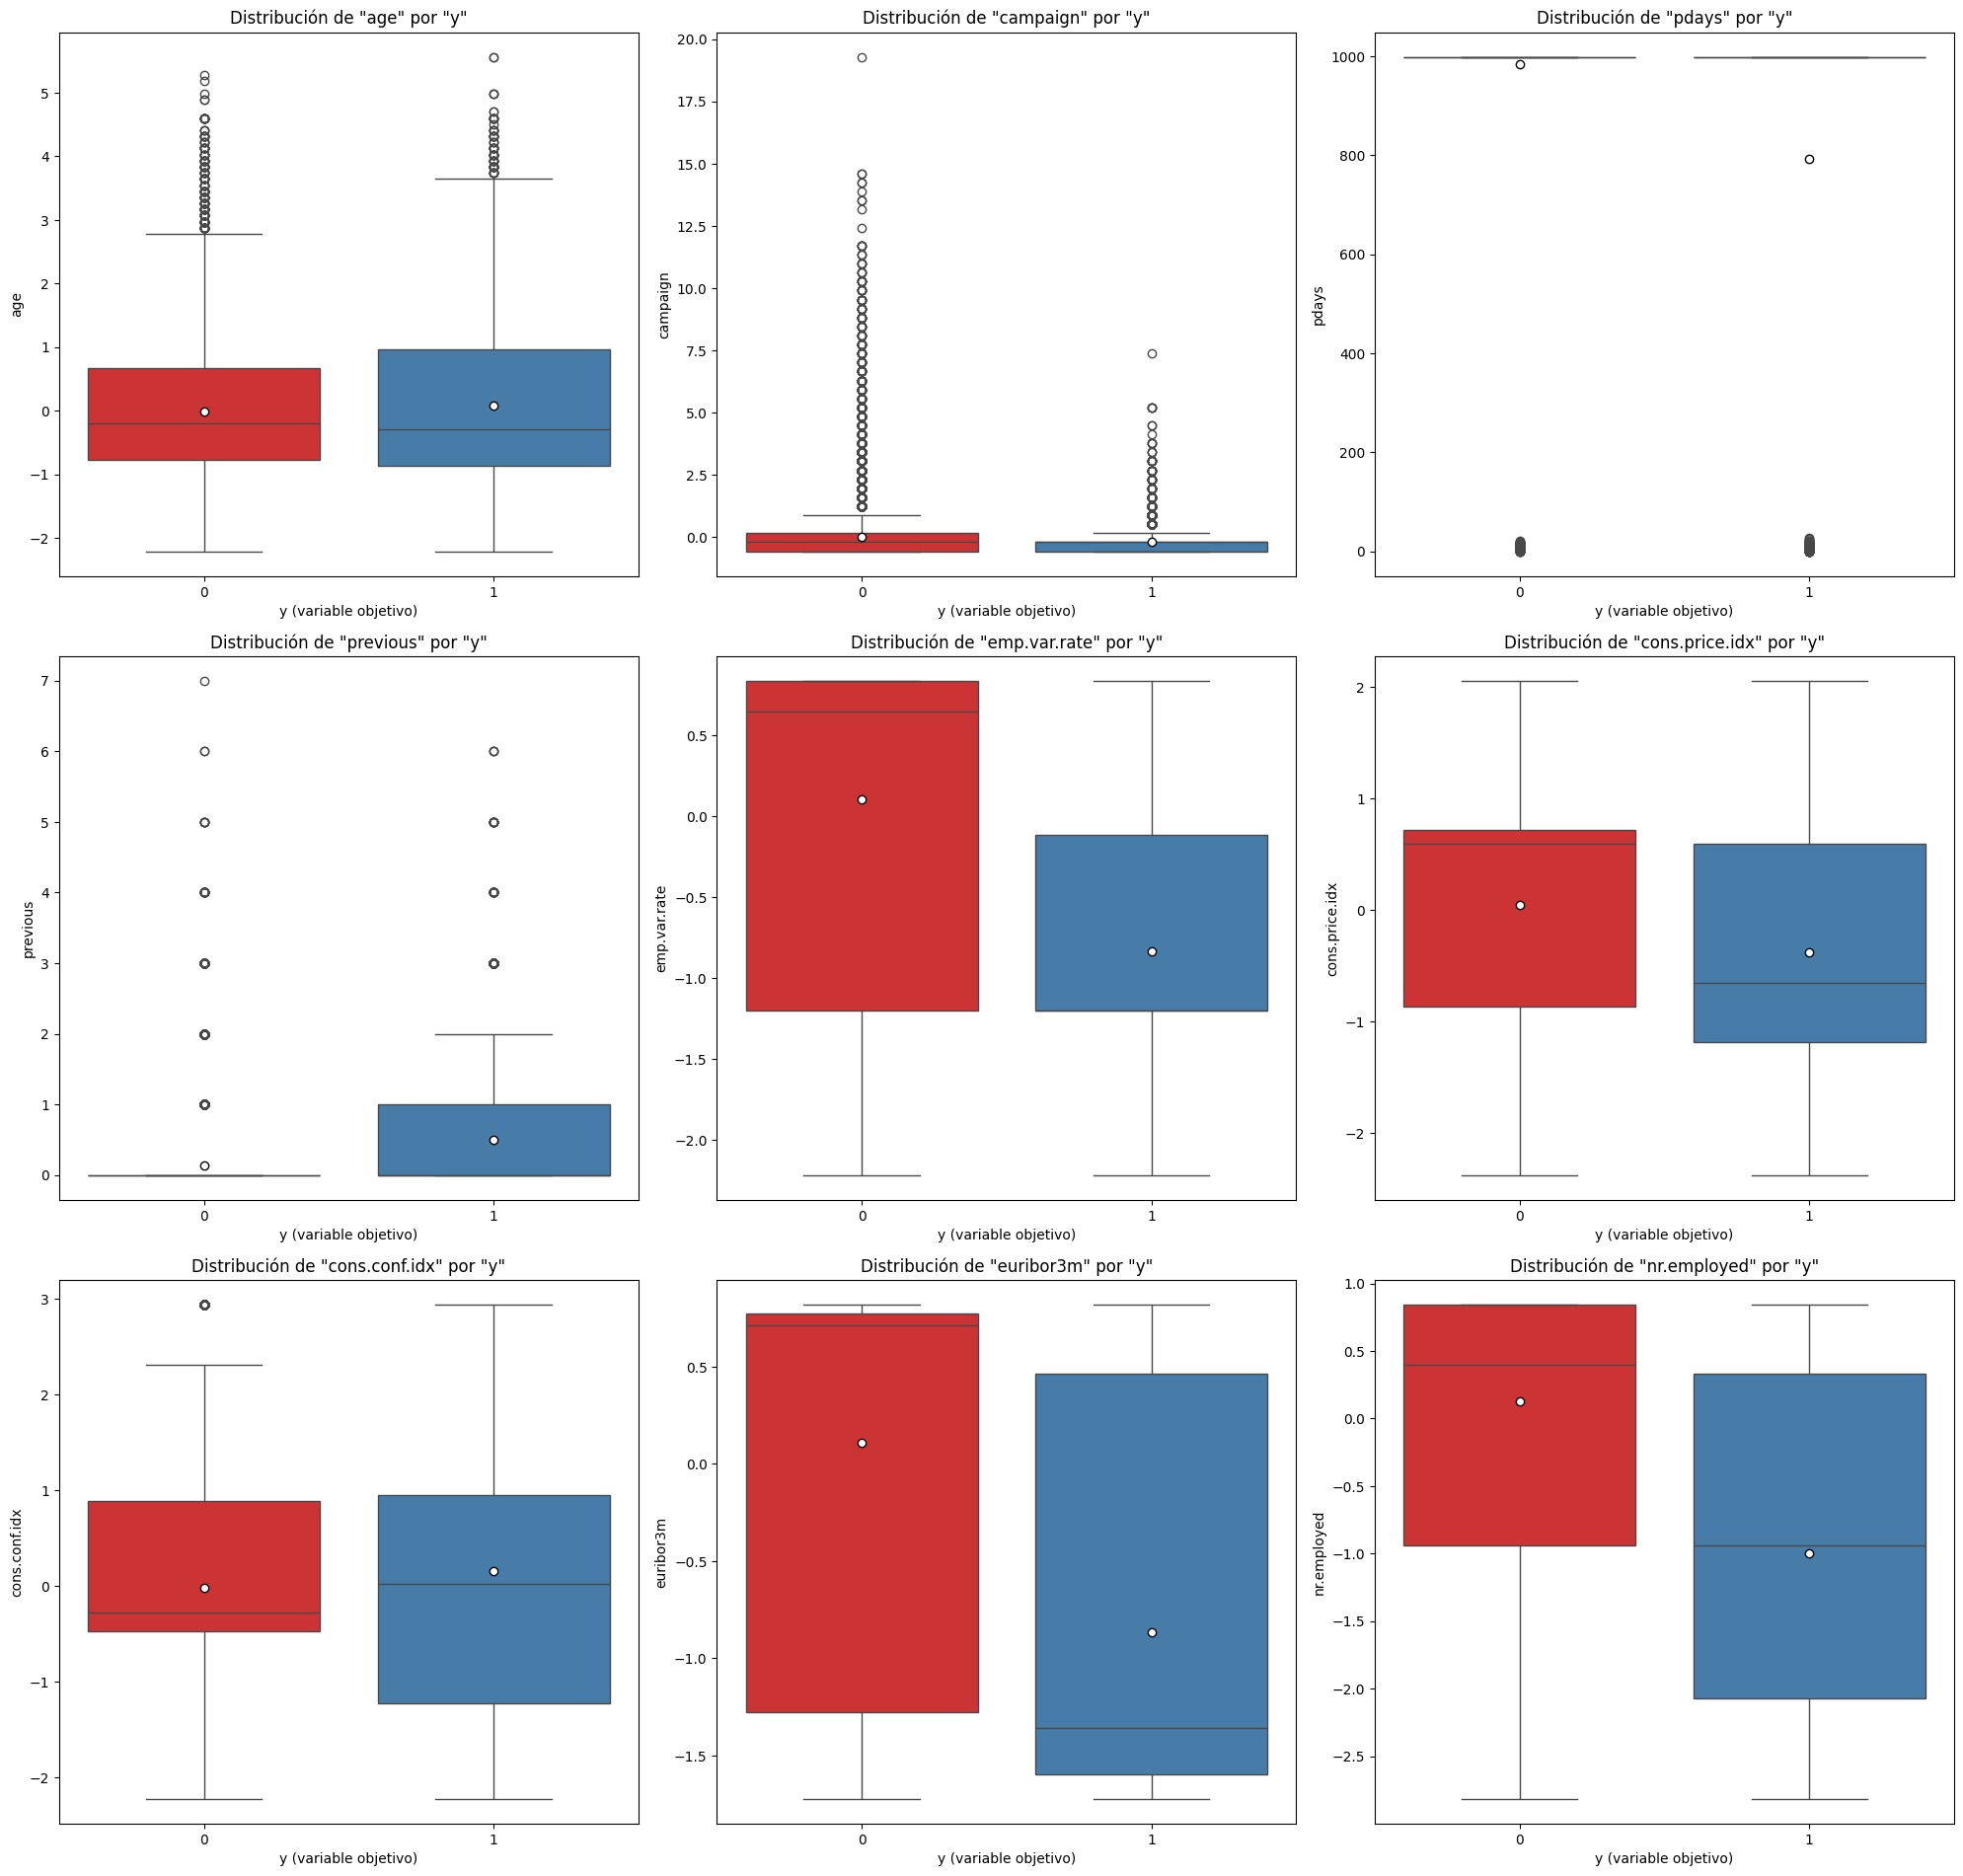

In [46]:
plt.figure(figsize=(20, 25))
plt.subplots_adjust(hspace=0.4, wspace=0.3)

for i, var in enumerate(continuas, 1):
    plt.subplot(4, 3, i)
    sns.boxplot(x='y', y=var, data=df, hue='y', palette='Set1', legend=False,
                showmeans=True, 
                meanprops={'marker':'o', 'markerfacecolor':'white', 'markeredgecolor':'black'})
    plt.title(f'Distribución de "{var}" por "y"')
    plt.xlabel('y (variable objetivo)')
    plt.ylabel(var)

# Eliminar subplots vacíos si es necesario
if len(continuas) < 12:
    for j in range(i + 1, 13):
        plt.delaxes(plt.subplot(4, 3, j))

plt.tight_layout()
plt.show()

A diferencia del anterior, aqui se encontro de manera muy inmediata que hay muchos valores atipicos, especialmente para las variables age, campaign y previous

Revisamos el contenido de previous y pdays tienen comportamientso similares (raros):

In [47]:
df['previous'].value_counts(normalize=True) * 100

previous
0.000   86.342
1.000   11.074
2.000    1.831
3.000    0.525
4.000    0.170
5.000    0.044
6.000    0.012
7.000    0.002
Name: proportion, dtype: float64

In [48]:
df['pdays'].value_counts(normalize=True) * 100

pdays
999.000   96.323
3.000      1.066
6.000      0.998
4.000      0.287
9.000      0.155
2.000      0.148
7.000      0.146
12.000     0.141
10.000     0.126
5.000      0.112
13.000     0.087
11.000     0.068
1.000      0.063
15.000     0.058
14.000     0.049
8.000      0.044
0.000      0.036
16.000     0.027
17.000     0.019
18.000     0.017
22.000     0.007
19.000     0.007
21.000     0.005
25.000     0.002
26.000     0.002
27.000     0.002
20.000     0.002
Name: proportion, dtype: float64

Con esto estamos seguros que es mejor agruparlo en 0 y 1

In [49]:
df['previous'] = df['previous'].apply(lambda x: 0 if x == 0 else 1)

#Lo majeramos de esta manera: 0 si no hubo contactos anteriores y 1 si el cliente si tuvo contactos anteiores

In [50]:
df['pdays'] = df['pdays'].apply(lambda x: 0 if x == 999 else 1)

#Lo majeramos de esta manera: 999 si el cliente no fue contactado y 1 si el cliente fue contactado anteriormente

### Outliers: Rango Intercuantil

Ahora vamos a aplicar el metodo del Rango Intercuartil para age, duration y campaign

In [51]:
# Calcular los cuartiles y el rango intercuartílico (IQR) para las variables numéricas
Q1 = df[['age', 'campaign']].quantile(0.25)
Q3 = df[['age', 'campaign']].quantile(0.75)
IQR = Q3 - Q1

# Filtrar los valores atípicos fuera del rango 1.5*IQR
df2 = df[~((df[['age', 'campaign']] < (Q1 - 1.5 * IQR)) | 
                     (df[['age', 'campaign']] > (Q3 + 1.5 * IQR))).any(axis=1)]

Vamos a corroborar que no se pierdan muchos valores al usar el metodo del Rango Intercuantil

In [52]:
len(df2) / len(df)

0.9069953849890697

Nos quedo un buen porcentaje de los valores, y ahora solo se corrobora como se comportan nuestros datos estadisticos despues de haber aplicado el metodo:

In [53]:
print("Antes de eliminar outliers:")
print(df[["age", "campaign"]].describe())

print("\nDespués de eliminar outliers:")
print(df2[["age", "campaign"]].describe())

Antes de eliminar outliers:
            age  campaign
count 41170.000 41170.000
mean     -0.000    -0.000
std       1.000     1.000
min      -2.209    -0.566
25%      -0.770    -0.566
50%      -0.194    -0.205
75%       0.670     0.156
max       5.565    19.287

Después de eliminar outliers:
            age  campaign
count 37341.000 37341.000
mean     -0.044    -0.225
std       0.930     0.407
min      -2.209    -0.566
25%      -0.770    -0.566
50%      -0.194    -0.205
75%       0.670     0.156
max       2.781     0.878


In [54]:
df=df2

In [55]:
del df2

In [56]:
# Recolectamos la basura para optimizar la memoria
gc.collect()

5617

In [57]:
df['y'].value_counts(normalize=True)

y
0   0.887
1   0.113
Name: proportion, dtype: float64

# Analisis de Multicolinealidad

Ya observamos la relacion entra cada variable y la variable objetivo, lo que se procedio a realizar fue la relacion entre las mismas variables (unicamente continuas), es decir todas contra todas, para ello nos apoyamos de un mapa de correlacion

In [58]:
# Calculamos la matriz de correlación
correlation_matrix = df[continuas].corr()

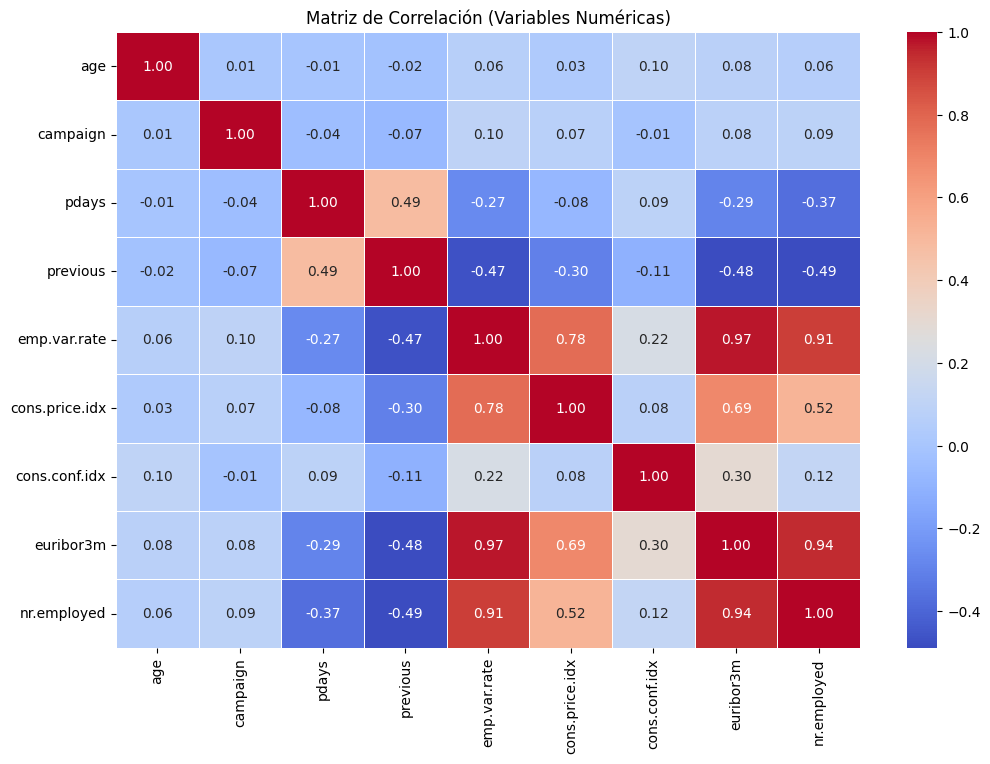

In [59]:
# Graficamos la matriz de correlación
plt.figure(figsize=(12,8))
sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap="coolwarm", linewidths=0.5)
plt.title("Matriz de Correlación (Variables Numéricas)")
plt.show()

Solo hay 4 valores muy altos (arriba de 0.75), estos son la correlacion entre **emp.var.rate, euribor3m, nr.employed y cons.price.idx** La descripcion de estas variables alude a aspectos socioeconomicos:

- emp.var.rate: Tasa de variación del empleo
- euribor3m: Tasa de interés Euribor a 3 meses
- nr.employed: Número de empleados en la economía
- cons.price.idx: Índice de precios al consumidor

Entonces vamos a hacer uso del **Analisis de Componentes Principales** para reducir la dimensionalidad

## Analisis de Componentes Principales (PCA)

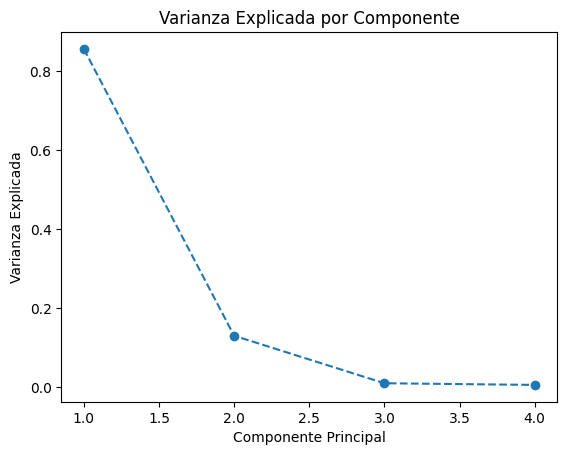

Varianza acumulada por los primeros componentes: [0.85660672 0.9861256  0.99518732 1.        ]


In [60]:
# Hacemos un subset con las varaibles correlacionadas
df_correl = df[['emp.var.rate', 'euribor3m', 'nr.employed', 'cons.price.idx']]

# Ajustar el PCA
pca = PCA()
pca.fit(df_correl)

# varianza explicada por cada componente
explained_variance = pca.explained_variance_ratio_

# Grafica
plt.plot(range(1, len(explained_variance) + 1), explained_variance, marker='o', linestyle='--')
plt.title('Varianza Explicada por Componente')
plt.xlabel('Componente Principal')
plt.ylabel('Varianza Explicada')
plt.show()

cumulative_variance = explained_variance.cumsum()
print("Varianza acumulada por los primeros componentes:", cumulative_variance)

La grafica nos muestra que realmente solo necesitamos agruparlo en dos componentes porque este explica el 98.6% de la varianza 

In [61]:
# Aplicamos la funcion PCA para reducir la dimensionalidad a solo un componente
pca = PCA(n_components=2)
componentes = pca.fit_transform(df_correl)
df[['PCA_economico1', 'PCA_economico2']] = componentes

In [62]:
# Eliminar las columnas originales y usar la nueva variable
df = df.drop(columns=['emp.var.rate', 'euribor3m', 'nr.employed', 'cons.price.idx'])

In [63]:
#La vamos a normalizar
scaler = MinMaxScaler()
df[['PCA_economico1', 'PCA_economico2']] = scaler.fit_transform(df[['PCA_economico1', 'PCA_economico2']])

In [64]:
continuas = ['age','campaign','pdays','previous', 'cons.conf.idx', 'PCA_economico1', 'PCA_economico2']

In [65]:
# Calculamos la matriz de correlación
correlation_matrix = df[continuas].corr()

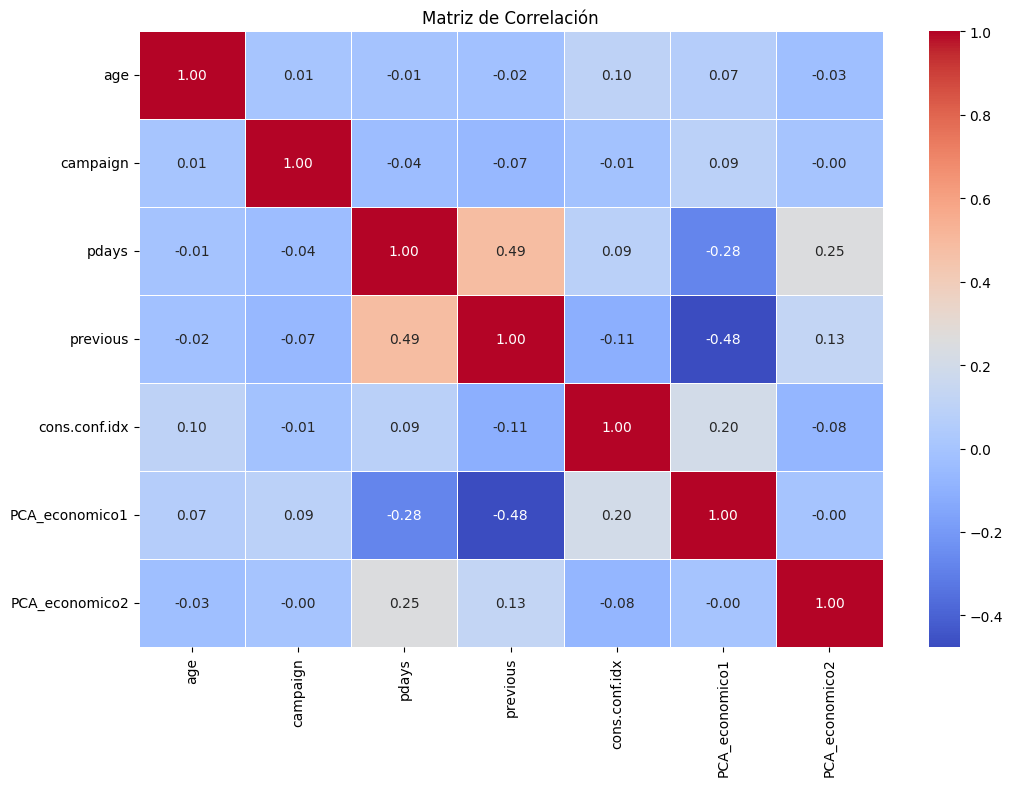

In [66]:
# Graficamos la matriz de correlación
plt.figure(figsize=(12,8))
sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap="coolwarm", linewidths=0.5)
plt.title("Matriz de Correlación")
plt.show()

In [67]:
# Recolectamos la basura para optimizar la memoria
gc.collect()

69514

# Creacion de variables

Esta seccion fue muy laboriosa porque muchas de las variables propuestas no servian dentro del modelo o eran muy rebuscadas de explicar

De igual forma lo tratamos de realizar para ayudar al modelo a que sea mas eficaz

### Relacion Inversa de la Edad y el Numero de Veces contactado

Con esta variable queremos explicar si a mayor edad los clientes son contactados menos veces ya que una persona joven podria acceder mas facilmente si se le acapara de llamadas, la variable se estandariza para que se homologue al reslto de valores

In [68]:
df['edad_camp'] = (df['age'] - df['campaign']) / df['age'].std()

### Contacto durante la semana

Es probable que dependiendo del dia en el que se haya buscado al cliente este pueda ser mas propoenso a aceptar el deposito a plazo fijo, principlamente el supuesto que creemos es que los fines de semana influencian en el resultado

In [69]:
df['contact_weekend'] = df['day_of_week'].apply(lambda x: 1 if x in [6, 7] else 0)

Revisamos la correlacion de las variables:

In [70]:
df[['edad_camp', 'contact_weekend', 'y']].corr()

,edad_camp,contact_weekend,y
edad_camp,1.000,NaN,-0.002
contact_weekend,NaN,NaN,NaN
y,-0.002,NaN,1.000


Y ahora me doy cuenta que no tengo ningun cliente que aceptara la oferta en fin de semana, entonces voy a eliminar la variable que cree:

In [71]:
df = df.drop(columns=['contact_weekend'])

Lo voy a sustituir solo por el viernes porque ese si es un valor que esta dentro de mis datos

In [72]:
df['viernes'] = (df['day_of_week'] == 5).astype(int)

In [73]:
print(df['viernes'].value_counts())  # Verificar distribución

viernes
0    30316
1     7025
Name: count, dtype: int64


In [74]:
df[['edad_camp', 'viernes', 'y']].corr()

,edad_camp,viernes,y
edad_camp,1.000,-0.005,-0.002
viernes,-0.005,1.000,-0.008
y,-0.002,-0.008,1.000


Ninguna de las variables tiene una fuerte correlacion por lo que no nos sirven dentro del modelo, asi que no las vamos a agregar y las borraremos 

In [75]:
df = df.drop(columns=['edad_camp'])

In [76]:
df = df.drop(columns=['viernes'])

Ninguna de las combinaciones nos permitio encontrar una nueva variable que ayudara al modelo.

In [77]:
#Vamos a cambiar los True y False
dummy = df.select_dtypes(include='bool').columns
df[dummy] = df[dummy].astype(int)

In [78]:
#Y movemos la Y de lugar
columna_y = df.pop('y')
df['y'] = columna_y   

# Construccion de la TAD

## Matriz de Predictoras

In [79]:
X = df.drop(columns=['y'])

In [80]:
y = df['y']

# Modelado: Regresion Logistica

### 2.3.1 Train-test split

In [81]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

### 2.3.2 Entrenamiento

Es el estimador de scikit-learn para modelos de clasificación binaria (en tu caso, predecir y = 0/1).

Funcionamiento: Calcula la probabilidad de que una observación pertenezca a la clase 1 usando una función logística (sigmoide).

In [82]:
#Tanto el penalty, como el solver son los parametros predefinidos de la funcion, unicamente colocamos class_weight porque hay 88%
#valores y que son 0, entonces puede que el modelo ignore el 1, con ese ajuste quedaria mejor para el modelo
model = LogisticRegression(penalty='l2', solver='liblinear', class_weight='balanced')
model.fit(X_train, y_train)

LogisticRegression(class_weight='balanced', solver='liblinear')

In [83]:
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix
# Predicciones
y_pred = model.predict(X_test)
y_proba = model.predict_proba(X_test)[:, 1]  # Probabilidades para clase 1

# Métricas
print("Classification Report:\n", classification_report(y_test, y_pred))
print("ROC-AUC:", roc_auc_score(y_test, y_proba))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))

Classification Report:
               precision    recall  f1-score   support

           0       0.95      0.78      0.86      9951
           1       0.28      0.68      0.40      1252

    accuracy                           0.77     11203
   macro avg       0.61      0.73      0.63     11203
weighted avg       0.88      0.77      0.80     11203

ROC-AUC: 0.7781453001496471
Confusion Matrix:
 [[7736 2215]
 [ 397  855]]


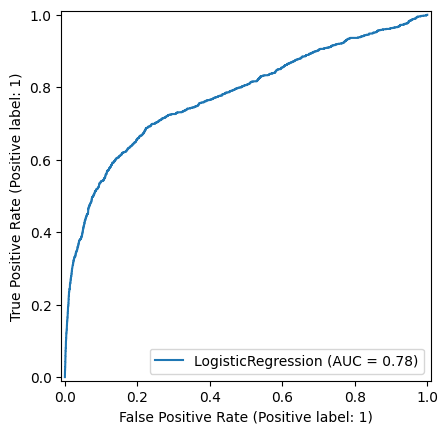

In [84]:
from sklearn.metrics import RocCurveDisplay
RocCurveDisplay.from_estimator(model, X_test, y_test)
plt.show()

Nuestro resultado fue un AUC (Area bajo la curva) de 0.78, lo que significa que el modelo tiene un desempeño decente para diferenciar entre casos positivos y negativos. Si bien no es perfecto, supera por buen margen el resultado aleatorio (0.5) y demuestra que el modelo está captando patrones útiles en los datos. Es evidente que dandole un mayor tratamiento o una mayor alimentacion de datos el modelo podria llegar a ser más preciso. En general, es un buen punto de partida, pero con mayores ajustes finos podríamos aumentar el nivel de confianza en las predicciones.

# Dashboard

El link del dashboard de la base original es el siguiente:

https://lookerstudio.google.com/reporting/a3f6496c-bfa7-49a3-bf8a-0cea92b42d06